# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [1]:
# importar librerías
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv("/datasets/users_latam.csv")
usage = pd.read_csv("/datasets/usage.csv")

In [3]:
# mostrar las primeras 5 filas de plans
plans.head()

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [4]:
# mostrar las primeras 5 filas de users
users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [5]:
# mostrar las primeras 5 filas de usage
usage.head()

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [6]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [7]:
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [8]:
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [9]:
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [10]:
# cantidad de nulos para users
print(users.isna().sum())
print(users.isna().mean())

user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [11]:
# cantidad de nulos para usage
print(usage.isna().sum())
print(usage.isna().mean())

id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?

users['city']: 469 valores faltantes. (11.7% del total de valores de la columna).
users['churn_date']: 3534 valores faltantes. (88% del total de valores de la columna).
usage['date']: 50 valores faltantes. (0.1% del total de valores de la columna).
usage['duration']: 22076 valores faltantes. (55% del total de valores de la columna).
usage['lenght']: 17896 valores faltantes. (44.7% del total de valores de la columna).
  
- Indica qué harías: ¿imputar, eliminar, ignorar?

    - users['city'] (11.7%): Dejar como nulos al no considerar que afecte la identificación de patrones de uso, la detección de comportamientos atípicos ni el estudio de las necesidades por segmentos de clientes.
    - users['churn_date'] (88%): Ignorar al no considerar que afecte la identificación de patrones de uso, la detección de comportamientos atípicos ni el estudio de las necesidades por segmentos de clientes.
    - usage['date']: Al ser el 1% imputar con la mediana.
    - usage['lenght']: Investigar correlaciones entre plan, edad y ciudad para determinar si imputamos con la media (o mediana) por grupos separados de existir dichas correlaciones. Si no existe relación, dejamos como nulos.

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [12]:
# explorar columnas numéricas de users
col_numericas_users = users[['user_id', 'age']]
col_numericas_users.describe()

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


In [13]:
wrong_age = (users['age'] <= -999).sum()
users_row_count = len(users)

print("Number of rows with Age= -999 : ")
print(wrong_age)
print("Percentage of rows with Age= -999 : ")
print((wrong_age / users_row_count)*100)

Number of rows with Age= -999 : 
55
Percentage of rows with Age= -999 : 
1.375


- La columna `user_id` muestra un comportamiento normal, no se aprecian valores atípicos.
- La columna `age` muestra sesgo hacia la izquierda, con valores imposibles a (-999).

In [14]:
# explorar columnas numéricas de usage
col_numericas_usage = usage[['id','user_id', 'duration','length']]
col_numericas_usage.describe()

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


In [15]:

# Filas sobre el percentil 99 Duration
duration_percentile99 = usage['duration'].quantile(0.99)
usage_row_count = len(usage)
duration_rows_above99 = (usage['duration']>duration_percentile99).sum()

print("Duration rows with duration above percentile 99: ")
print(duration_rows_above99)
print("Percentage of duration rows with duration above percentile 99: ")
print((duration_rows_above99/usage_row_count)*100)

print()
# Filas sobre el percentil 99 Length
lenght_percentile99 = usage['length'].quantile(0.99)
lenght_rows_above99 = (usage['length']>lenght_percentile99).sum()

print("Length rows with duration above percentile 99: ")
print(lenght_rows_above99)
print("Percentage of length rows with duration above percentile 99: ")
print((lenght_rows_above99/usage_row_count)*100)


Duration rows with duration above percentile 99: 
180
Percentage of duration rows with duration above percentile 99: 
0.44999999999999996

Length rows with duration above percentile 99: 
216
Percentage of length rows with duration above percentile 99: 
0.54


- Las columnas `id` y `user_id`muestran comportamientos normales, no se aprecian valores atípicos.

- Las columnas `duration` y `length` muestran un valor máximo muy por encima del cuartil 3, valores a investigar antes de determinar si imputar o
 eliminar.

In [16]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']
print(users[columnas_user].value_counts().sort_index(level='city',ascending=False))
print(users[columnas_user].value_counts(normalize=True).sort_index(level='city',ascending=False))

city      plan   
Medellín  Premium    218
          Basico     398
MTY       Premium    132
          Basico     275
GDL       Premium    152
          Basico     298
Cali      Premium    162
          Basico     262
CDMX      Premium    256
          Basico     474
Bogotá    Premium    286
          Basico     522
?         Premium     31
          Basico      65
dtype: int64
city      plan   
Medellín  Premium    0.061739
          Basico     0.112716
MTY       Premium    0.037383
          Basico     0.077882
GDL       Premium    0.043047
          Basico     0.084395
Cali      Premium    0.045879
          Basico     0.074200
CDMX      Premium    0.072501
          Basico     0.134240
Bogotá    Premium    0.080997
          Basico     0.147833
?         Premium    0.008779
          Basico     0.018408
dtype: float64


- La columna `city` muestra 6 ciudades (Medellin, MTY, GDL, Cali, CDMX y Bogotá), también contiene 96 filas nulas (?), representa el 2,7% del total. Ignoraremos los valores nulos al no representar una parte significativa del total de datos.
- La columna `plan` muestra 2 valores posibles (Premium y Basico).

In [17]:
# explorar columna categórica de usage
print(usage['type'].value_counts())

text    22092
call    17908
Name: type, dtype: int64


- La columna `type` muestra 2 valores posibles (text y call).


---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  

- ¿En qué columnas encontraste valores inválidos o sentinels?

    - users[`age`] muestra sesgo hacia la izquierda, con valores imposibles a (-999).
    - usage[`duration`, `length`] muestran un valor máximo muy por encima del cuartil 3.
    - users[`city`] contiene 96 filas nulas (?), representa el 2,7% del total.
       

- ¿Qué acción tomarías?

    - users[`age`], los valores imposibles son 55 y representan un 1,37%, al no representar una porción importante, procederemos a imputar estos valores con la mediana.
    - usage[`duration`] los valores por encima del percentil 99 son 180 (0.45%) por lo que procederemos a realizar mayor análisis para verificar la fiabilidad de los datos verificando si corresponden a un segmento específico de clientes. De no ser fiables, procederemos a winsorizar y reemplazar los valores que se encuentren por encima con el percentil 99
    - usage[`length`] los valores por encima del percentil 99 son 20091 (50.2%) por lo que requiere mayor análisis para determinar la veracidad de los valores y como proceder con ellos.

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [18]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')

In [19]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'], errors='coerce')

In [20]:
# Revisar los años presentes en `reg_date` de users
users['year'] = pd.to_datetime(users['reg_date'], errors='coerce').dt.year
users['month'] = pd.to_datetime(users['reg_date'], errors='coerce').dt.month
users.groupby(['year', 'month']).size()

year  month
2022  1        110
      2        102
      3        110
      4        110
      5        111
      6        109
      7        113
      8        112
      9        107
      10       112
      11       108
      12       110
2023  1        114
      2        102
      3        112
      4        106
      5        111
      6        109
      7        111
      8        109
      9        108
      10       113
      11       108
      12       113
2024  1        113
      2        106
      3        113
      4        108
      5        114
      6        108
      7        113
      8        114
      9        109
      10       113
      11       110
      12       109
2026  5         40
dtype: int64

En `reg_date`, se aprecian fechas comprendidas entre enero 2022 y Diciembre 2024. No aparece el año 2025 y aparece Mayo del 2026.

In [21]:
# Revisar los años presentes en `date` de usage
usage['year'] = pd.to_datetime(usage['date'], errors='coerce').dt.year
usage['month'] = pd.to_datetime(usage['date'], errors='coerce').dt.month
usage.groupby(['year', 'month']).size()


year    month
2024.0  1.0      6843
        2.0      6403
        3.0      6837
        4.0      6622
        5.0      6843
        6.0      6402
dtype: int64

In [22]:
print("Nulos")
usage['year'].isna().sum()

Nulos


50

En `date`, sólo se aprecia el año 2024, los meses entre enero y junio y 50 fechas nulas.
Basaremos el análisis en estas fechas.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
      - En users aparece el año 2026 y meses posteriores a junio del 2024 por lo que se pueden catalogar como fechas no transcurridas, si tomamos de base las fechas de usage que solo llega al año 2024, mes de Junio. También aparecen años anteriores como 2023 y 2022.
- ¿Qué harías con ellas?
      - Únicamente considerar las fechas que se encuentran en ambos datasets (usage, users) para mantener la consistencia en el análisis.

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [23]:
# Reemplazar -999 por la mediana de age
age_mediana = users['age'].median()
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.122250
std        17.690408
min        18.000000
25%        33.000000
50%        47.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [24]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace("?", "NA")

# Verificar cambios
users['city'].value_counts()

Bogotá      808
CDMX        730
Medellín    616
GDL         450
Cali        424
MTY         407
NA           96
Name: city, dtype: int64

In [25]:
# Marcar fechas futuras como NA para reg_date
users['reg_date'] = pd.to_datetime(users['reg_date'], errors = "coerce").dt.normalize()
limit_date = pd.Timestamp("2024-06-30")
users['future_date'] = users['reg_date'] > limit_date  
users.loc[users['future_date'], 'reg_date'] = pd.NaT
# Verificar cambios
users['reg_date'].describe()

count                    3292
unique                    912
top       2023-03-07 00:00:00
freq                        4
first     2022-01-01 00:00:00
last      2024-06-30 00:00:00
Name: reg_date, dtype: object

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [26]:
# Verificación MAR en usage (Missing At Random) para duration
usage['duration'].isna().groupby(usage['type']).mean().sort_values(ascending = False)

type
text    0.999276
call    0.000000
Name: duration, dtype: float64

In [27]:
# Verificación MAR en usage (Missing At Random) para length
usage['length'].isna().groupby(usage['type']).mean().sort_values(ascending = False)

type
call    0.99933
text    0.00000
Name: length, dtype: float64

`duration` y `length` expresan missingness dependiente de 'type', los valores nulos solo se expresan en "call" y en una proporción de 0.99 en ambas.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [28]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas


# Agrupar información por usuario
usage_agg = usage.groupby("user_id").agg({"is_text":"sum", "is_call":"sum", "duration":"sum"}).reset_index()

# observar resultado
usage_agg.head(3)

,user_id,is_text,is_call,duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [29]:
# Renombrar columnas
usage_agg = usage_agg.rename(columns={"is_text":"cant_mensajes","is_call":"cant_llamadas","duration":"cant_minutos_llamada"})
# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [30]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = pd.merge(users, usage_agg, on=['user_id'],how='left')
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,year,month,future_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01,Basico,NaN,2022,1,False,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,NA,2022-01-01,Basico,NaN,2022,1,False,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01,Basico,NaN,2022,1,False,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01,Premium,NaN,2022,1,False,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02,Basico,NaN,2022,1,False,4.0,3.0,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [31]:
# Resumen estadístico de las columnas numéricas
user_profile.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 4000 entries, 0 to 3999
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   user_id               4000 non-null   int64         
 1   first_name            4000 non-null   object        
 2   last_name             4000 non-null   object        
 3   age                   4000 non-null   float64       
 4   city                  3531 non-null   object        
 5   reg_date              3292 non-null   datetime64[ns]
 6   plan                  4000 non-null   object        
 7   churn_date            466 non-null    object        
 8   year                  4000 non-null   int64         
 9   month                 4000 non-null   int64         
 10  future_date           4000 non-null   bool          
 11  cant_mensajes         3999 non-null   float64       
 12  cant_llamadas         3999 non-null   float64       
 13  cant_minutos_llama

In [32]:
# Distribución porcentual del tipo de plan
user_profile['plan'].value_counts(normalize = True)

Basico     0.64875
Premium    0.35125
Name: plan, dtype: float64

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

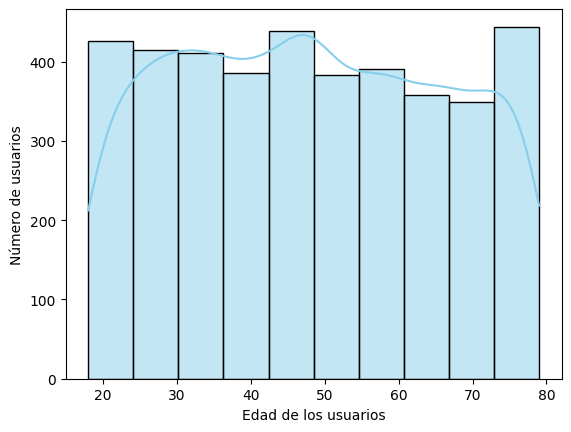

In [33]:
# Histograma para visualizar la edad (age)

sns.histplot(user_profile['age'],bins=10,color='skyblue',kde=True)
plt.xlabel('Edad de los usuarios')
plt.ylabel('Número de usuarios')
plt.show()

💡Insights: 
- Distribución aplanada, no existen picos y se evidencia variabilidad alta. Los clientes se encuentran entre los 20 y menos de 80 años.

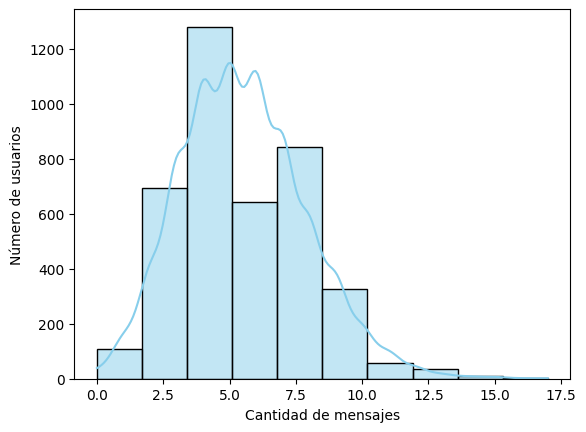

In [34]:
# Histograma para visualizar la cant_mensajes
sns.histplot(user_profile['cant_mensajes'],bins=10,color='skyblue',kde=True)
plt.xlabel('Cantidad de mensajes')
plt.ylabel('Número de usuarios')
plt.show()


💡Insights: 
- Se evidencia una distribución picuda, con un moderado sesgo a la derecha, el pico más alto se evidencia en los 5 mensajes por usuario.

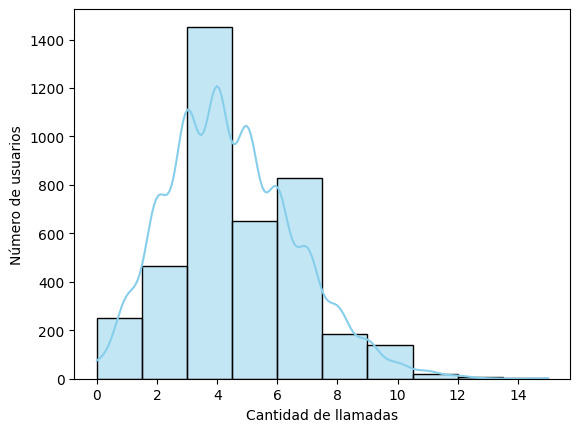

In [35]:
# Histograma para visualizar la cant_llamadas
sns.histplot(user_profile['cant_llamadas'],bins=10,color='skyblue',kde=True)
plt.xlabel('Cantidad de llamadas')
plt.ylabel('Número de usuarios')
plt.show()

💡Insights: 
- Distribución picuda, con sesgo moderado a la derecha, el pico más alto se evidencia en las 4 llamadas por usuario.

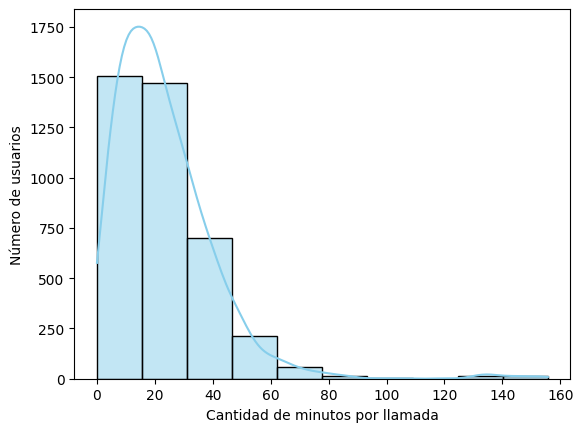

In [36]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(user_profile['cant_minutos_llamada'],bins=10,color='skyblue',kde=True)
plt.xlabel('Cantidad de minutos por llamada')
plt.ylabel('Número de usuarios')
plt.show()

💡Insights: 
- Se evidencia un marcado sesgo a la derecha, se observa un pico entre los 10 y 20 minutos por llamada 

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

In [60]:
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

user_profile[columnas_numericas].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99])

,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,3999.000000,3999.000000,3999.000000
mean,48.122250,5.524381,4.478120,23.317054
std,17.690408,2.358416,2.144238,18.168095
min,18.000000,0.000000,0.000000,0.000000
1%,18.000000,1.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.120000
50%,47.000000,5.000000,4.000000,19.780000
75%,63.000000,7.000000,6.000000,31.415000
99%,79.000000,12.000000,10.000000,82.197600
max,79.000000,17.000000,15.000000,155.690000


In [61]:
p90 = user_profile['cant_minutos_llamada'].quantile(0.90)
print("10% de usuarios con mas minutos por llamada")
(user_profile['cant_minutos_llamada'] > p90).sum()

10% de usuarios con mas minutos por llamada


400

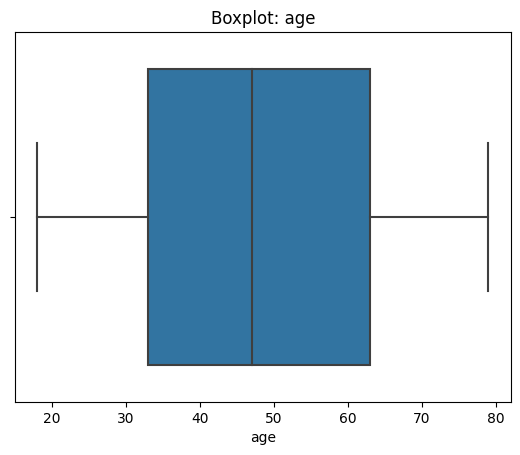

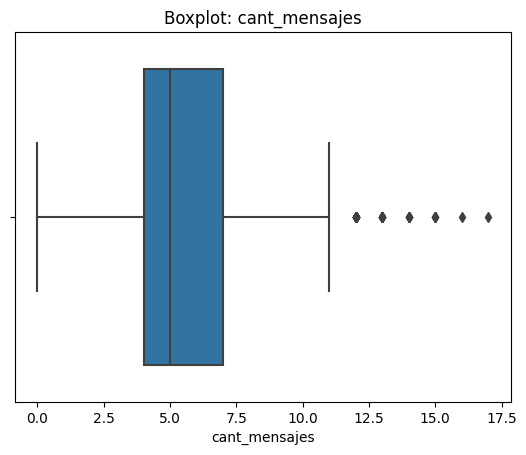

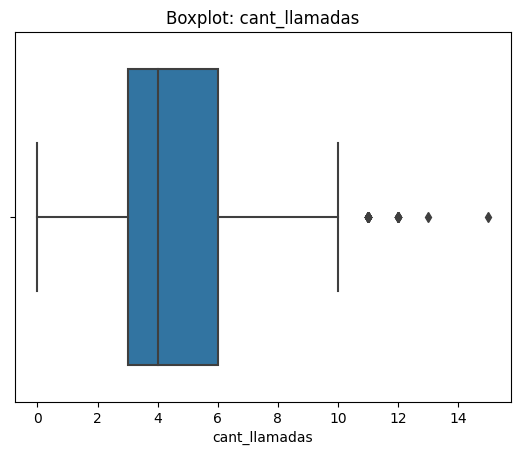

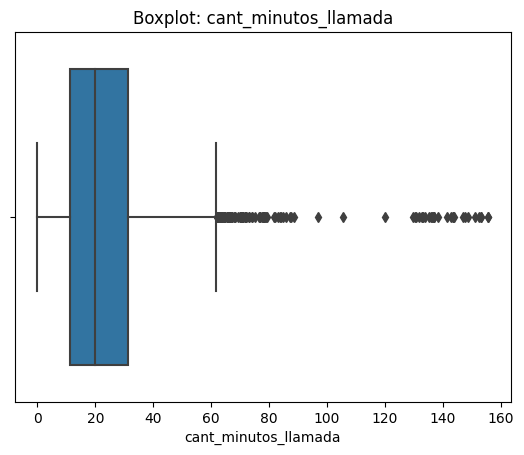

In [37]:
# Visualizando usando BoxPlot 

columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    plt.figure()
    sns.boxplot(data = user_profile, x = col)
    plt.title(f'Boxplot: {col}')
    plt.show()


💡Insights: 
- Age: No presenta outliers, la caja tiene un tamaño normal, al igual que los bigotes que muestran el rango típico de valores. La mediana está en valores medios.
- cant_mensajes: Muestra outliers hacia la derecha y la caja es pequeña. La mediana está en valores bajos, indicativo de que la mayoría de usuarios envía pocos mensajes y un pequeño sector de clientes envía más mensajes que el restante Q4, los outliers son valores altos posibles.
- cant_llamadas: Muestra outliers hacia la derecha, el bigote derecho es ligeramente más amplio y la caja es pequeña. La mediana está en valores bajos, la mayoría de usuarios realiza pocas llamadas. Los outliers son valores altos posibles.
- cant_minutos_llamada: Muestra muchos outliers hacia la derecha, incluyendo outliers extremos, la caja es pequeña y el bigote derecho es más amplio que el izquierdo. La mediana está en valores muy bajos, la mayoría de usuarios realiza llamadas de poca duración. Los outliers son valores altos posibles.

In [38]:
# Calcular límites con el método IQR
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_limites:
    Q1 = user_profile[col].quantile(0.25)
    Q3 = user_profile[col].quantile(0.75)
    IQR = Q3 -Q1
    limite_superior = Q3 + 1.5 * IQR
    print(f'{col}: límite superior = {limite_superior}')

cant_mensajes: límite superior = 11.5
cant_llamadas: límite superior = 10.5
cant_minutos_llamada: límite superior = 61.8575


In [39]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,23.317054
std,2.358416,2.144238,18.168095
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.120000
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.415000
max,17.000000,15.000000,155.690000


💡Insights: 
- cant_mensajes: mantener outliers, al no ser extremos y poder ser representativo de un segmento de clientes.
- cant_llamadas: mantener outliers, al no ser extremos y poder ser representativo de un segmento de clientes.
- cant_minutos_llamada: mantener outliers, a pesar de ser extremos pueden entregar informacion valiosa de uso de los planes por segmentos de edad u otros.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [40]:
# Crear columna grupo_uso	cant_llamadas	cant_minutos_llamada	

def use_segment(row) :

    mensajes = row['cant_mensajes']
    llamadas = row['cant_llamadas']

    if llamadas < 5 and mensajes < 5:
        return "Bajo uso"
    elif llamadas < 10 and mensajes < 10:
        return "Uso medio"
    else:
        return "Alto uso"

user_profile['grupo_uso'] = user_profile.apply(use_segment, axis=1)


In [41]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,year,month,future_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01,Basico,NaN,2022,1,False,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,NA,2022-01-01,Basico,NaN,2022,1,False,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01,Basico,NaN,2022,1,False,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01,Premium,NaN,2022,1,False,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02,Basico,NaN,2022,1,False,4.0,3.0,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [42]:
# Crear columna grupo_edad
def age_segment(row) :

    age = row['age']

    if age < 30:
        return "Joven"
    elif age < 60:
        return "Adulto"
    else:
        return "Adulto Mayor"

user_profile['grupo_edad'] = user_profile.apply(age_segment, axis=1)


In [43]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,year,month,future_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01,Basico,NaN,2022,1,False,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,NA,2022-01-01,Basico,NaN,2022,1,False,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01,Basico,NaN,2022,1,False,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01,Premium,NaN,2022,1,False,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02,Basico,NaN,2022,1,False,4.0,3.0,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

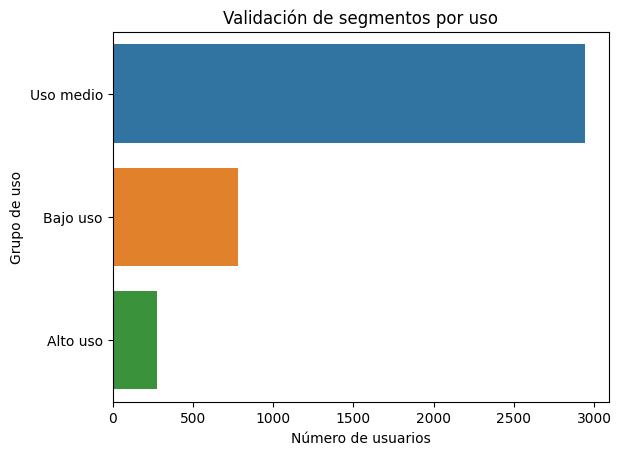

In [44]:
# Visualización de los segmentos por uso

sns.countplot(data = user_profile, y='grupo_uso', order=user_profile['grupo_uso'].value_counts().index)
plt.ylabel('Grupo de uso')
plt.xlabel('Número de usuarios')
plt.title('Validación de segmentos por uso')
plt.show()


In [45]:
user_profile['grupo_uso'].value_counts()

Uso medio    2943
Bajo uso      778
Alto uso      279
Name: grupo_uso, dtype: int64

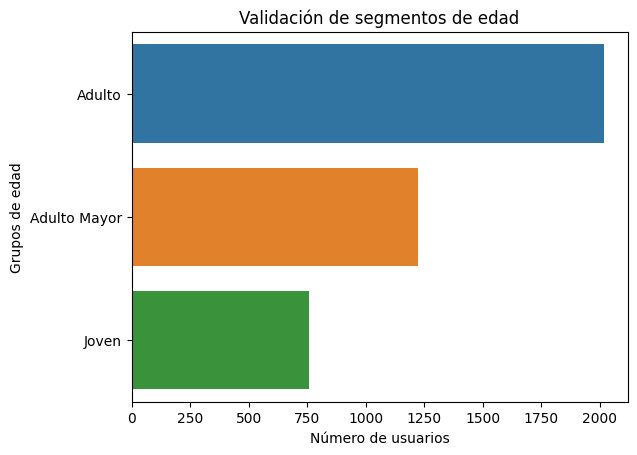

In [46]:
# Visualización de los segmentos por edad
sns.countplot(data = user_profile, y='grupo_edad', order=user_profile['grupo_edad'].value_counts().index)
plt.ylabel('Grupos de edad')
plt.xlabel('Número de usuarios')
plt.title('Validación de segmentos de edad')
plt.show()


In [47]:
user_profile['grupo_edad'].value_counts()

Adulto          2018
Adulto Mayor    1222
Joven            760
Name: grupo_edad, dtype: int64

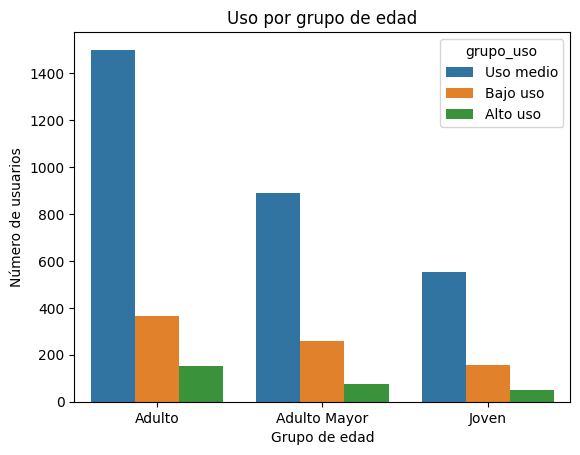

In [48]:

sns.countplot(data=user_profile, x='grupo_edad', hue='grupo_uso', order=user_profile['grupo_edad'].value_counts().index,hue_order=user_profile['grupo_uso'].value_counts().index)
plt.xlabel('Grupo de edad')
plt.ylabel('Número de usuarios')
plt.title('Uso por grupo de edad')
plt.show()


In [63]:
pd.crosstab(user_profile['grupo_edad'], user_profile['grupo_uso'])

grupo_uso,Alto uso,Bajo uso,Uso medio
grupo_edad,,,
Adulto,154,364,1500
Adulto Mayor,74,257,891
Joven,51,157,552


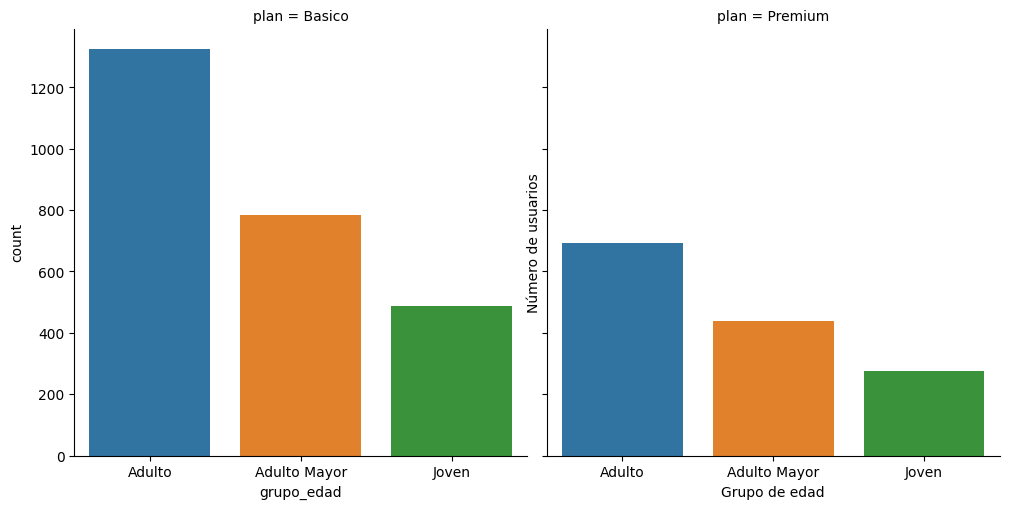

In [49]:
sns.catplot(data=user_profile, x='grupo_edad', col='plan', kind='count', order=user_profile['grupo_edad'].value_counts().index)
plt.ylabel('Número de usuarios')
plt.xlabel('Grupo de edad')
plt.show()

In [50]:
user_profile.value_counts(['plan'])

plan   
Basico     2595
Premium    1405
dtype: int64

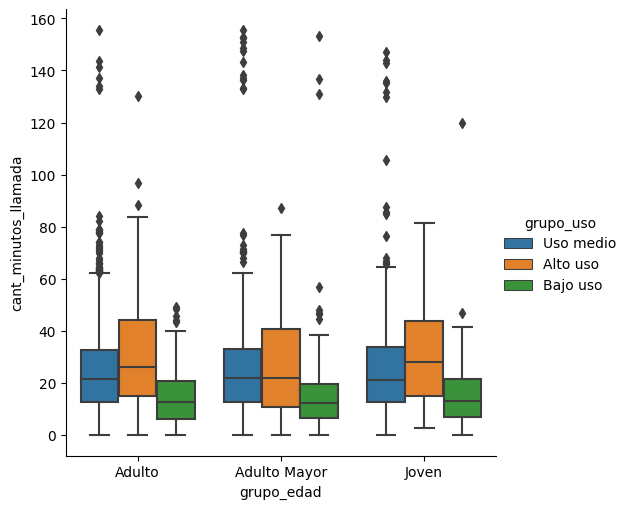

In [51]:
g = sns.catplot(data=user_profile, x='grupo_edad', y='cant_minutos_llamada', hue='grupo_uso', kind='box')
plt.show()


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- **¿Qué problemas tenían originalmemte los datos? ¿Qué porcentaje, o cantidad de filas, de esa columna representaban?**

Inicialmente los datos presentaban valores nulos y outliers,

- users['city']: 469 valores faltantes. (11.7% del total de valores de la columna).
- users['churn_date']: 3534 valores faltantes. (88% del total de valores de la columna).
- usage['date']: 50 valores faltantes. (0.1% del total de valores de la columna).
- usage['duration']: 22076 valores faltantes. (55% del total de valores de la columna). 180 filas con outliers. Expresa missingness dependiente de 'type'.
- usage['lenght']: 17896 valores faltantes. (44.7% del total de valores de la columna). 216 filas con outliers. Expresa missingness dependiente de 'type'.
- users['age']: 55 filas con outliers con valores imposibles (-999). (1.3% del total de valores de la columna).

- **¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?**

Existen 3 segmentos de clientes según su edad: Adulto, Adulto Mayor y Joven. También existen 3 segmentos de clientes según su nivel de uso Alto uso, Bajo uso y uso medio. 
La mayoría de los usuarios expresan un Uso Medio en todos los segmentos de edad y en general, adicionalmente los jovenes son el segmento más pequeño. En todos los segmentos de uso, los adultos representan a la mayoría de los usuarios. Adicionalmente el plan más contratado es el básico y es mayormente contratrado por adultos, al igual que el plan premium.

- **¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?**

Los adultos, estos representan la mayor porción de clientes de ConnectaTel, además de esto, también son quienes más contratan planes premium además de mostrar un uso más alto de los planes, por lo cual se pueden crear planes orientados a las necesidades de este segmento.
  
- **¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?**

En la duración de las llamadas se aprecia un valor máximo de 155.690000, casi 7 veces la mediana (23). Se evidencian outliers extremos significativos en los 3 segmentos de edades en la duración de las llamadas para los grupos de uso medio, por lo que se puede adaptar una solución o producto que genere mayor rentabilidad de este segmento de clientes.

- **¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?**

Crear planes orientados a clientes adultos y adultos mayores, segmentando por sus tipos de consumo, reevaluando la oferta y beneficios incluidos en los planes básicos y premium, para motivar la migración de clientes de planes básicos a planes premium, por ejemplo, ofreciendo mayor cantidad de tiempo de llamada a los clientes premium o limitando algunos de los beneficios en los planes básicos para hacer más atractiva la oferta de los planes premium. 

✍️ **Escribe aquí tu análisis ejecutivo:**

Contexto, objetivo y cobertura de datos: Análisis de los patrones de uso de servicios y planes de telefonía para detectar comportamientos atípicos y comprender que segmentos de clientes muestran necesidades diferenciadas, con el fin de optimizar la oferta comercial y mejorar la experiencia del usuario. Partiendo de los dos segmentos: Grupo de edad (joven, usuarios menores a 30 años; adulto, usuarios menores a 60 años; adultos mayores, usuarios a partir de los 60 años). Segmento de uso (Bajo uso, menos de 5 llamadas y 5 mensajes. Uso medio, menos de 10 llamadas y 10 mensajes. Alto uso, a partir de 10 llamadas y 10 mensajes).


El segmento de uso más predominante es el de Uso Medio, con 2943 usuarios, más de la mitad del total de usuarios, el uso Alto es el de menor recurrencia, con 279 usuarios. En cuanto a la edad, la mayoria de los usuarios son Adultos (2018), seguido por los adultos mayores (1222) y por último la menor porción de los usuarios son jovenes (760). Respecto al uso, el 99% de los usuarios envían entre 1 y 12 mensajes, realizan entre 0 y 10 llamadas y la duración de las llamadas está entre 0 y 82 minutos.

En el uso medio, podemos apreciar outliers extremos en los minutos por llamada, dichos outliers son muy significativos si se considera que el uso alto presenta muy pocos outliers extremos entre todos los segmentos de edad. Esto puede significar que en los usuarios de uso medio tenemos un sector de clientes con un volumen alto de minutos, a este sector se puede apuntar para aumentar la venta de planes premium, evaluando la posibilidad de diferenciar las ofertas de minutos entre el plan básico y el plan premium, limitando los minutos que se ofrecen en el plan básico a un límite que no afecte al percentil 90 de los usuarios, serían 400 usuarios que se puede proyectar rentabilizar partiendo de los minutos por llamada. 
Adicionalmente, los adultos siendo el segmento predominante debe ser priorizado en futuras campañas en todos los segmentos de uso, enfocar más recursos al crecimiento del alto uso mediante el mejoramiento de la calidad de las llamadas e impulsando mejoras o innovaciones en los servicios de mensajería que impulsen el uso de estos servicios en el segmento de adultos.



### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
- users['city']: 469 valores faltantes. (11.7% del total de valores de la columna).
- users['churn_date']: 3534 valores faltantes. (88% del total de valores de la columna).
- usage['date']: 50 valores faltantes. (0.1% del total de valores de la columna).
- usage['duration']: 22076 valores faltantes. (55% del total de valores de la columna). 180 filas con outliers. Expresa missingness dependiente de 'type'.
- usage['lenght']: 17896 valores faltantes. (44.7% del total de valores de la columna). 216 filas con outliers. Expresa missingness dependiente de 'type'.
- users['age']: 55 filas con outliers con valores imposibles (-999). (1.3% del total de valores de la columna).


🔍 **Segmentos por Edad**

- Joven, ususarios menores a 30 años. Es el segmento con menor volumen de usuarios, 760 en total, poco menos de la mitad de usuarios adultos del segmento de uso medio.
- Adulto, usuarios menores a 60 años. Es el segmento con mayor volumen de usuarios en todos los niveles de uso, alto uso con 154, bajo uso 364 y uso medio, el uso de mayor volumen 1500. Para un total de 2018 usuarios.
- Adulto Mayor, usuarios mayores a 60 años. Número de usuarios: 1222.


📊 **Segmentos por Nivel de Uso**

- Bajo uso, menos de 5 mensajes y menos de 5 llamadas. 778 usuarios.
- Uso medio, menos de 10 mensajes y menos de 10 llamadas. 2943 usuarios.
- Alto uso, 10 mensajes o más y 10 llamadas o más. 279 usuarios.

➡️ Esto sugiere que el segmento de edad más importante es el de los adultos y el segmento más importante en nivel de uso es el uso medio, ambos segmentos están significativamente por encima del resto de su categoría. La diferencia en volumen de usuarios también sugiere que el segmento joven no se siente atraído por la oferta actual, reportando los valores más pequeños en todos los segmentos de uso, lo que podría dar lugar a crecimiento en caso de ofrecer soluciones tecnológicas atractivas adaptadas al segmento joven. 


💡 **Recomendaciones**
- Enfocar recursos a los segmentos adulto y uso medio, al ser los segmentos mayoritarios se pueden crear campañas que mejoren la experiencia del cliente y optimicen la rentabilización del uso de los planes, reevaluando los beneficios de los planes para promover la migración del uso medio al uso alto y promoviendo el crecimiento del volumen de usuarios en planes premium que generen mayores rentas a la compañia.
- Mejorar el volumen de usuarios jovenes creando soluciones enfocadas en hacer la oferta más atractiva para los usuarios menores de 30 años, ofreciendo planes adaptados a sus necesidades, incluyendo y adaptando servicios que capten más usuarios jovenes como la posibilidad de modernizar los servicios de mensajería añadiendo la posibilidad de enviar stickers, archivos adjuntos y mejorando la visualización de los portales de mensajería, entre otras. 

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`